# 1. Setup & Libraries

In [ ]:
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("Ready, seed =", SEED)

Ready, seed = 42


# 2. AHCD Dataset Loading

In [ ]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download("mloey1/ahcd1")
print("Path:", path)

for f in glob.glob(path + "/**/*", recursive=True):
    if os.path.isfile(f):
        print(f, "|", round(os.path.getsize(f)/1e6, 1), "MB")

Streaming output truncated to the last 5000 lines.
/kaggle/input/ahcd1/Test Images 3360x32x32/test/id_612_label_26.png | 0.0 MB
/kaggle/input/ahcd1/Test Images 3360x32x32/test/id_403_label_6.png | 0.0 MB
/kaggle/input/ahcd1/Test Images 3360x32x32/test/id_658_label_21.png | 0.0 MB
/kaggle/input/ahcd1/Test Images 3360x32x32/test/id_1653_label_15.png | 0.0 MB
/kaggle/input/ahcd1/Test Images 3360x32x32/test/id_2595_label_10.png | 0.0 MB
/kaggle/input/ahcd1/Test Images 3360x32x32/test/id_2506_label_21.png | 0.0 MB
/kaggle/input/ahcd1/Test Images 3360x32x32/test/id_1286_label_27.png | 0.0 MB
/kaggle/input/ahcd1/Test Images 3360x32x32/test/id_47_label_24.png | 0.0 MB
/kaggle/input/ahcd1/Test Images 3360x32x32/test/id_2093_label_11.png | 0.0 MB
/kaggle/input/ahcd1/Test Images 3360x32x32/test/id_1284_label_26.png | 0.0 MB
/kaggle/input/ahcd1/Test Images 3360x32x32/test/id_737_label_5.png | 0.0 MB
/kaggle/input/ahcd1/Test Images 3360x32x32/test/id_327_label_24.png | 0.0 MB
/kaggle/input/ahcd1/Te

In [ ]:
csvs = sorted(glob.glob(path + "/**/*.csv", recursive=True))
data = {}
for f in csvs:
    df = pd.read_csv(f, header=None)
    data[os.path.basename(f)] = df
    print(os.path.basename(f), "->", df.shape)

csvTestImages 3360x1024.csv -> (3360, 1024)
csvTestLabel 3360x1.csv -> (3360, 1)
csvTrainImages 13440x1024.csv -> (13440, 1024)
csvTrainLabel 13440x1.csv -> (13440, 1)
csvTestImages 3360x1024.csv -> (3360, 1024)
csvTestLabel 3360x1.csv -> (3360, 1)
csvTrainImages 13440x1024.csv -> (13440, 1024)
csvTrainLabel 13440x1.csv -> (13440, 1)
csvTestImages 3360x1024.csv -> (3360, 1024)
csvTestLabel 3360x1.csv -> (3360, 1)
csvTrainImages 13440x1024.csv -> (13440, 1024)
csvTrainLabel 13440x1.csv -> (13440, 1)


In [ ]:
def find_csv(keyword):
    matches = [f for f in csvs if keyword in os.path.basename(f)]
    return matches[0]

X_train = pd.read_csv(find_csv("csvTrainImages"), header=None).values.astype("float32")
y_train = pd.read_csv(find_csv("csvTrainLabel"), header=None).values.ravel()
X_test  = pd.read_csv(find_csv("csvTestImages"), header=None).values.astype("float32")
y_test  = pd.read_csv(find_csv("csvTestLabel"), header=None).values.ravel()

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())
print("Labels range:", y_train.min(), "to", y_train.max())
print("Number of classes:", len(np.unique(y_train)))

X_train: (13440, 1024) | y_train: (13440,)
X_test: (3360, 1024) | y_test: (3360,)
Pixel range: 0.0 to 255.0
Labels range: 1 to 28
Number of classes: 28


# 3. AHCD Data Exploration

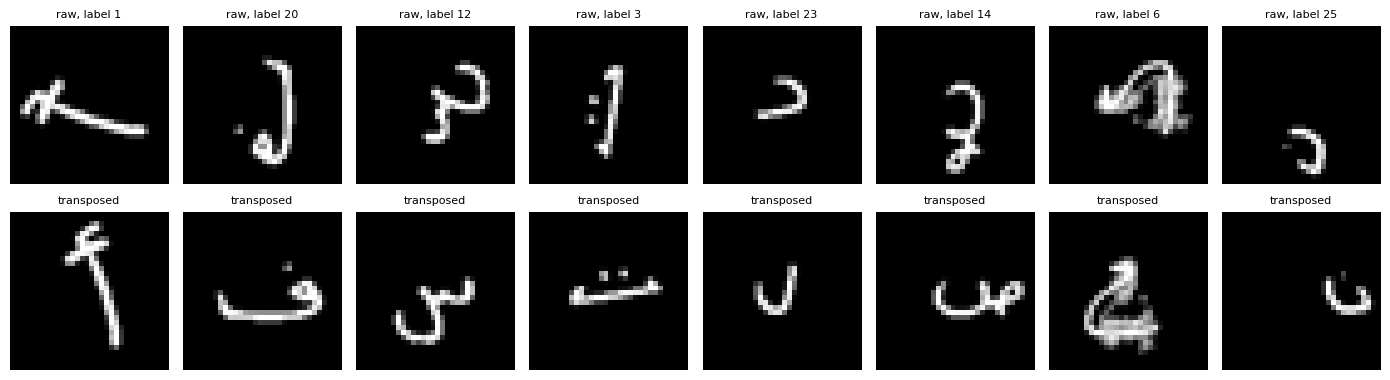

In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    img = X_train[i * 1500].reshape(32, 32)
    axes[0, i].imshow(img, cmap="gray")
    axes[0, i].set_title(f"raw, label {y_train[i * 1500]}", fontsize=8)
    axes[0, i].axis("off")
    axes[1, i].imshow(img.T, cmap="gray")
    axes[1, i].set_title("transposed", fontsize=8)
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()

1     480
2     480
3     480
4     480
5     480
6     480
7     480
8     480
9     480
10    480
11    480
12    480
13    480
14    480
15    480
16    480
17    480
18    480
19    480
20    480
21    480
22    480
23    480
24    480
25    480
26    480
27    480
28    480


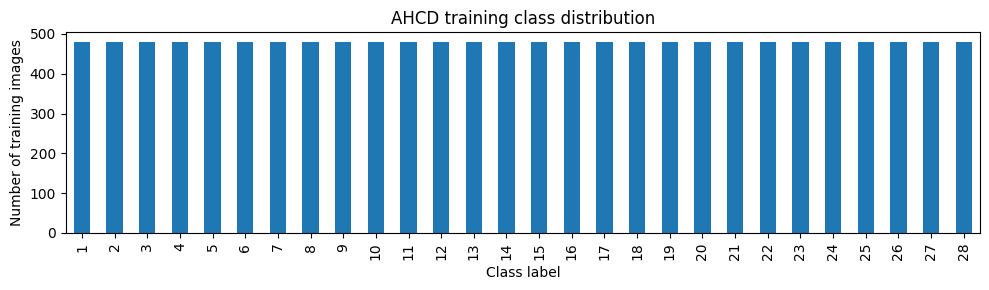

In [ ]:
train_counts = pd.Series(y_train).value_counts().sort_index()
print(train_counts.to_string())

plt.figure(figsize=(10, 3))
train_counts.plot(kind="bar")
plt.xlabel("Class label")
plt.ylabel("Number of training images")
plt.title("AHCD training class distribution")
plt.tight_layout()
plt.show()

# 4. AHCD Preprocessing

In [ ]:
from sklearn.model_selection import train_test_split

def preprocess(X):
    X = X.reshape(-1, 32, 32).transpose(0, 2, 1)
    X = X / 255.0
    return X[..., np.newaxis].astype("float32")

X_tr_full = preprocess(X_train)
X_te = preprocess(X_test)
y_tr_full = (y_train - 1).astype("int64")
y_te = (y_test - 1).astype("int64")

X_tr, X_val, y_tr, y_val = train_test_split(
    X_tr_full, y_tr_full,
    test_size=0.1, stratify=y_tr_full, random_state=SEED
)

print("Train:", X_tr.shape, "| Val:", X_val.shape, "| Test:", X_te.shape)
print("Labels range:", y_tr.min(), "to", y_tr.max())
print("Pixel range:", X_tr.min(), "to", X_tr.max())

Train: (12096, 32, 32, 1) | Val: (1344, 32, 32, 1) | Test: (3360, 32, 32, 1)
Labels range: 0 to 27
Pixel range: 0.0 to 1.0


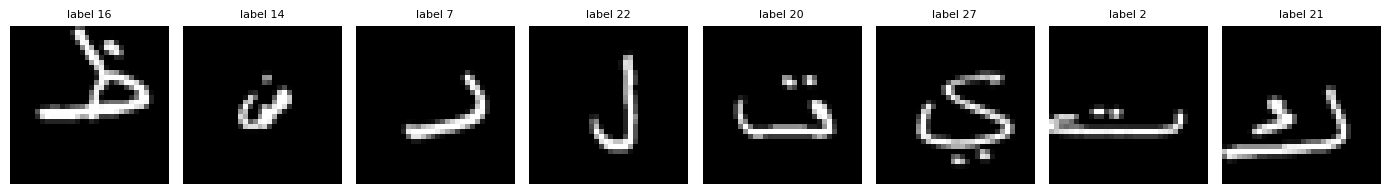

In [ ]:
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for i in range(8):
    axes[i].imshow(X_tr[i, :, :, 0], cmap="gray")
    axes[i].set_title(f"label {y_tr[i]}", fontsize=8)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

# 5. Saving AHCD Data

In [ ]:
os.makedirs("processed", exist_ok=True)
np.savez_compressed(
    "processed/ahcd_processed.npz",
    X_train=X_tr, y_train=y_tr,
    X_val=X_val, y_val=y_val,
    X_test=X_te, y_test=y_te,
)
print("Saved:", os.listdir("processed"))

Saved: ['proposed_cnn.keras', 'per_letter_accuracy.png', 'ahcd_processed.npz', 'results_zero_shot.csv', 'hijja_isolated.npz', 'per_letter_accuracy.csv', 'hijja_split.npz', 'confusion_matrix.png', 'baseline_cnn.keras', 'results_multiseed.csv']


# 6. Hijja Dataset Loading & Exploration

In [ ]:
!git clone -q https://github.com/israksu/Hijja2.git
hijja_root = "Hijja2"

for root, dirs, files in os.walk(hijja_root):
    if ".git" in root:
        continue
    print(root, "| dirs:", len(dirs), "| files:", len(files))
    for f in files[:5]:
        print("    ", f)

fatal: destination path 'Hijja2' already exists and is not an empty directory.
Hijja2 | dirs: 30 | files: 4
     ~$letterStats.xlsx
     CSV.zip
     README.md
     letterStats.xlsx
Hijja2/5 gim | dirs: 4 | files: 1
     .DS_Store
Hijja2/5 gim/5.3 | dirs: 0 | files: 463
     41310.png
     35642.png
     43420.png
     7577.png
     18917.png
Hijja2/5 gim/5.4 | dirs: 0 | files: 464
     38883.png
     40819.png
     23562.png
     14166.png
     46687.png
Hijja2/5 gim/5.2 | dirs: 0 | files: 458
     46527.png
     43419.png
     31552.png
     31228.png
     38042.png
Hijja2/5 gim/5.1 | dirs: 0 | files: 472
     5847.png
     39005.png
     22695.png
     47383.png
     48328.png
Hijja2/16 da | dirs: 4 | files: 0
Hijja2/16 da/16.3 | dirs: 0 | files: 527
     2862.png
     21221.png
     485.png
     44575.png
     12905.png
Hijja2/16 da/16.2 | dirs: 0 | files: 423
     15604.png
     41997.png
     9015.png
     9664.png
     12148.png
Hijja2/16 da/16.1 | dirs: 0 | files: 452
     1981

In [ ]:
import re
from PIL import Image

rows = []
for letter_dir in sorted(os.listdir(hijja_root)):
    letter_path = os.path.join(hijja_root, letter_dir)
    if not os.path.isdir(letter_path) or letter_dir.startswith("."):
        continue
    for sub in sorted(os.listdir(letter_path)):
        sub_path = os.path.join(letter_path, sub)
        if os.path.isdir(sub_path):
            n = len([f for f in os.listdir(sub_path) if f.endswith(".png")])
            rows.append((letter_dir, sub, n))

summary = pd.DataFrame(rows, columns=["letter_folder", "subfolder", "n_images"])
print(summary.to_string())
print("Total images:", summary["n_images"].sum())

sample = os.path.join(hijja_root, rows[0][0], rows[0][1])
img = Image.open(os.path.join(sample, os.listdir(sample)[0]))
print("Sample image size:", img.size, "| mode:", img.mode)

    letter_folder subfolder  n_images
0          1 alif       1.1       456
1          1 alif       1.2       443
2          1 alif       1.3       460
3          1 alif       1.4       460
4          1 alif       1.5       464
5          1 alif       1.6       458
6           10 ra      10.1       424
7           10 ra      10.2       423
8          11 zay      11.1       426
9          11 zay      11.2       434
10         12 sin      12.1       440
11         12 sin      12.2       427
12         12 sin      12.3       425
13         12 sin      12.4       437
14        13 shin      13.1       439
15        13 shin      13.2       412
16        13 shin      13.3       436
17        13 shin      13.4       420
18         14 sad      14.1       438
19         14 sad      14.2       427
20         14 sad      14.3       437
21         14 sad      14.4       421
22         15 dad      15.1       432
23         15 dad      15.2       402
24         15 dad      15.3       433
25         1

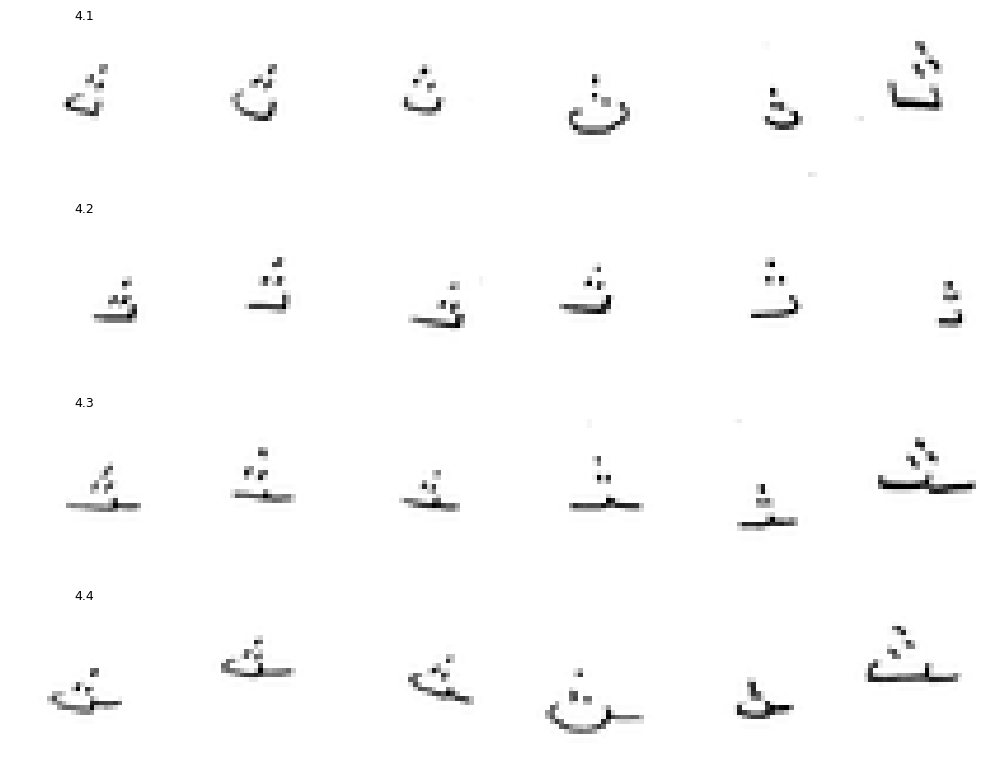

In [ ]:
letter_folder = "4 tha"
subs = sorted(d for d in os.listdir(os.path.join(hijja_root, letter_folder))
              if os.path.isdir(os.path.join(hijja_root, letter_folder, d)))

fig, axes = plt.subplots(len(subs), 6, figsize=(10, 2 * len(subs)))
for r, sub in enumerate(subs):
    folder = os.path.join(hijja_root, letter_folder, sub)
    files = sorted(os.listdir(folder))[:6]
    for c, fname in enumerate(files):
        axes[r, c].imshow(Image.open(os.path.join(folder, fname)).convert("L"), cmap="gray")
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(sub, fontsize=9)
plt.tight_layout()
plt.show()

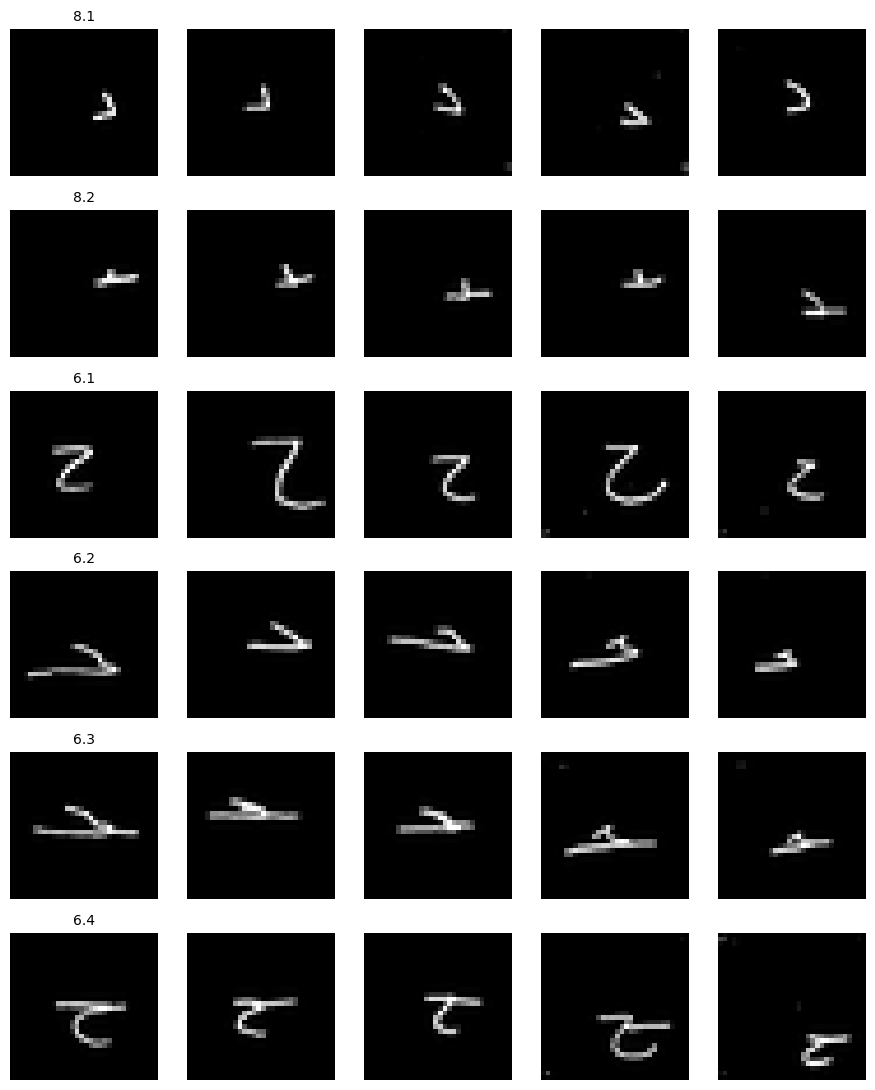

In [ ]:
from PIL import ImageOps

fig, axes = plt.subplots(6, 5, figsize=(9, 11))
row = 0
for letter_folder in ["8 dal", "6 ha"]:
    subs = sorted(d for d in os.listdir(os.path.join(hijja_root, letter_folder))
                  if os.path.isdir(os.path.join(hijja_root, letter_folder, d)))
    for sub in subs:
        folder = os.path.join(hijja_root, letter_folder, sub)
        files = sorted(os.listdir(folder))[:5]
        for c, fname in enumerate(files):
            img = ImageOps.invert(Image.open(os.path.join(folder, fname)).convert("L"))
            axes[row, c].imshow(img, cmap="gray")
            axes[row, c].axis("off")
            if c == 0:
                axes[row, c].set_title(sub, fontsize=10)
        row += 1
plt.tight_layout()
plt.show()

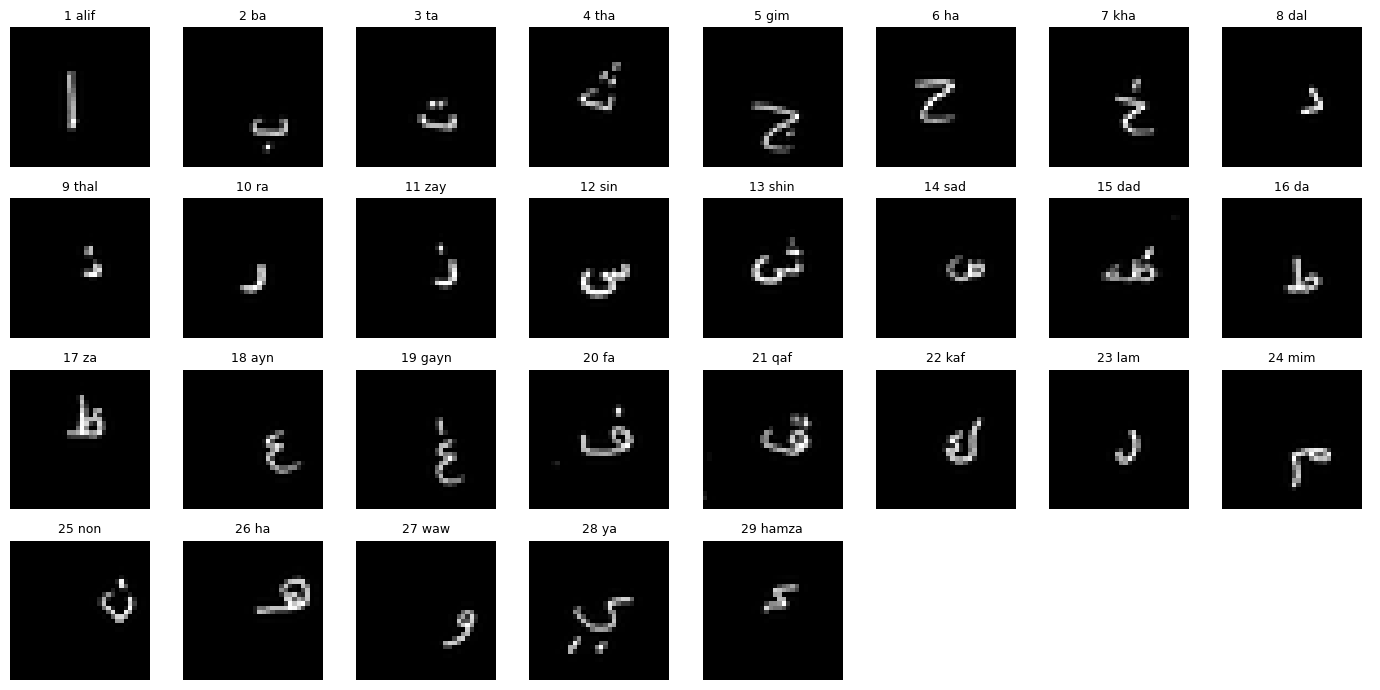

Letters found: 29


In [ ]:
letters = sorted(
    [d for d in os.listdir(hijja_root) if re.match(r"^\d+ ", d)],
    key=lambda d: int(d.split()[0]),
)

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for ax in axes.ravel():
    ax.axis("off")

for ax, letter in zip(axes.ravel(), letters):
    num = letter.split()[0]
    folder = os.path.join(hijja_root, letter, num + ".1")
    fname = sorted(os.listdir(folder))[0]
    img = ImageOps.invert(Image.open(os.path.join(folder, fname)).convert("L"))
    ax.imshow(img, cmap="gray")
    ax.set_title(letter, fontsize=9)

plt.tight_layout()
plt.show()
print("Letters found:", len(letters))

# 7. Hijja Preprocessing & Label Alignment

In [ ]:
def load_hijja_isolated(root):
    X, y = [], []
    for letter in letters:
        num = int(letter.split()[0])
        if num == 29:
            continue
        folder = os.path.join(root, letter, str(num) + ".1")
        for fname in sorted(os.listdir(folder)):
            if not fname.endswith(".png"):
                continue
            img = Image.open(os.path.join(folder, fname)).convert("L")
            X.append(255 - np.asarray(img, dtype="uint8"))
            y.append(num - 1)
    X = np.stack(X).astype("float32") / 255.0
    return X[..., np.newaxis], np.array(y, dtype="int64")

X_h, y_h = load_hijja_isolated(hijja_root)

print("Hijja isolated:", X_h.shape, "| labels:", y_h.min(), "to", y_h.max())
print("Classes:", len(np.unique(y_h)))
print("Pixel range:", X_h.min(), "to", X_h.max())
print("Mean pixel  Hijja:", round(float(X_h.mean()), 3), "| AHCD:", round(float(X_te.mean()), 3))

counts = pd.Series(y_h).value_counts().sort_index()
print("Images per class: min", counts.min(), "| max", counts.max())

os.makedirs("processed", exist_ok=True)
np.savez_compressed("processed/hijja_isolated.npz", X=X_h, y=y_h)
print("Saved:", os.listdir("processed"))

Hijja isolated: (12351, 32, 32, 1) | labels: 0 to 27
Classes: 28
Pixel range: 0.0 to 1.0
Mean pixel  Hijja: 0.025 | AHCD: 0.053
Images per class: min 422 | max 472
Saved: ['proposed_cnn.keras', 'per_letter_accuracy.png', 'ahcd_processed.npz', 'results_zero_shot.csv', 'hijja_isolated.npz', 'per_letter_accuracy.csv', 'hijja_split.npz', 'confusion_matrix.png', 'baseline_cnn.keras', 'results_multiseed.csv']


# 8. CNN Model Architectures

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(SEED)
NUM_CLASSES = 28

def build_baseline():
    return models.Sequential([
        layers.Input(shape=(32, 32, 1)),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="baseline_cnn")

def build_proposed():
    return models.Sequential([
        layers.Input(shape=(32, 32, 1)),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="proposed_cnn")

baseline = build_baseline()
proposed = build_proposed()
baseline.summary()
proposed.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_25 (Conv2D)              │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 28)             │       114,716 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 133,532 (521.61 KB)

 Trainable params: 133,532 (521.61 KB)

 Non-trainable params: 0 (0.00 B)

Model: "proposed_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_27 (Conv2D)              │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_28 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 28)             │         3,612 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 96,668 (377.61 KB)

 Trainable params: 96,476 (376.86 KB)

 Non-trainable params: 192 (768.00 B)

# 9. Model Training

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

EPOCHS = 30
BATCH = 64
LR = 1e-3

def train_model(build_fn, name):
    tf.keras.utils.set_random_seed(SEED)
    model = build_fn()
    model.compile(
        optimizer=tf.keras.optimizers.Adam(LR),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    hist = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH,
        callbacks=[stop],
        verbose=0
    )

    test_loss, test_acc = model.evaluate(X_te, y_te, verbose=0)

    print(
        name,
        "| epochs run:", len(hist.history["loss"]),
        "| best val acc:", round(max(hist.history["val_accuracy"]), 4),
        "| TEST acc:", round(test_acc, 4)
    )

    model.save("processed/" + name + ".keras")
    return model, hist

baseline, hist_b = train_model(build_baseline, "baseline_cnn")
proposed, hist_p = train_model(build_proposed, "proposed_cnn")

baseline_cnn | epochs run: 13 | best val acc: 0.8743 | TEST acc: 0.8827
proposed_cnn | epochs run: 19 | best val acc: 0.9479 | TEST acc: 0.9557


# 10. Evaluation & Results

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(
    X_h, y_h, test_size=0.2, stratify=y_h, random_state=SEED
)
np.savez_compressed("processed/hijja_split.npz",
                    X_train=Xh_tr, y_train=yh_tr, X_test=Xh_te, y_test=yh_te)

def evaluate(model, X, y):
    pred = model.predict(X, verbose=0).argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(
        y, pred, average="macro", zero_division=0
    )
    return accuracy_score(y, pred), p, r, f1

rows = []
for name, m in [("baseline", baseline), ("proposed", proposed)]:
    for ds, (X, y) in [("AHCD test", (X_te, y_te)),
                       ("Hijja test (no fine-tuning)", (Xh_te, yh_te))]:
        acc, p, r, f1 = evaluate(m, X, y)
        rows.append([name, ds, round(acc, 4), round(p, 4), round(r, 4), round(f1, 4)])

results = pd.DataFrame(
    rows, columns=["model", "test set", "accuracy", "macro precision", "macro recall", "macro F1"]
)
print("Hijja train:", Xh_tr.shape, "| Hijja test:", Xh_te.shape)
print(results.to_string(index=False))
results.to_csv("processed/results_zero_shot.csv", index=False)

Hijja train: (9880, 32, 32, 1) | Hijja test: (2471, 32, 32, 1)
   model                    test set  accuracy  macro precision  macro recall  macro F1
baseline                   AHCD test    0.8827           0.8863        0.8827    0.8832
baseline Hijja test (no fine-tuning)    0.3982           0.5332        0.3977    0.3977
proposed                   AHCD test    0.9557           0.9575        0.9557    0.9556
proposed Hijja test (no fine-tuning)    0.5204           0.6958        0.5201    0.5479


# 11. Hijja Fine-Tuning Experiments


In [ ]:
import time
FT_LR, FT_EPOCHS, FT_BATCH = 1e-4, 20, 32
FRACTIONS = [0.05, 0.10, 0.25]

def finetune(base_model, frac, seed=SEED):
    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.models.clone_model(base_model)
    model.set_weights(base_model.get_weights())
    Xs, _, ys, _ = train_test_split(
        Xh_tr, yh_tr, train_size=frac, stratify=yh_tr, random_state=seed
    )
    model.compile(optimizer=tf.keras.optimizers.Adam(FT_LR),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(Xs, ys, epochs=FT_EPOCHS, batch_size=FT_BATCH, verbose=0)
    return model, len(Xs)

rows = []
t0 = time.time()
for name, m in [("baseline", baseline), ("proposed", proposed)]:
    acc, p, r, f1 = evaluate(m, Xh_te, yh_te)
    rows.append([name, 0.0, 0, round(acc, 4), round(f1, 4)])
    for frac in FRACTIONS:
        ft, n = finetune(m, frac)
        acc, p, r, f1 = evaluate(ft, Xh_te, yh_te)
        rows.append([name, frac, n, round(acc, 4), round(f1, 4)])

ft_results = pd.DataFrame(
    rows, columns=["model", "fraction of Hijja train", "images", "accuracy", "macro F1"]
)
print(ft_results.to_string(index=False))
print("Fine-tuning time (s):", round(time.time() - t0))

   model  fraction of Hijja train  images  accuracy  macro F1
baseline                     0.00       0    0.3982    0.3977
baseline                     0.05     494    0.5629    0.5618
baseline                     0.10     988    0.6002    0.5982
baseline                     0.25    2470    0.6346    0.6334
proposed                     0.00       0    0.5204    0.5479
proposed                     0.05     494    0.7353    0.7344
proposed                     0.10     988    0.7859    0.7873
proposed                     0.25    2470    0.8377    0.8382
Fine-tuning time (s): 63


# 12. Multi-Seed Evaluation


In [ ]:
SEEDS = [42, 43, 44]
all_rows = []
t0 = time.time()

for seed in SEEDS:
    for name, build_fn in [("baseline", build_baseline), ("proposed", build_proposed)]:
        tf.keras.utils.set_random_seed(seed)
        m = build_fn()
        m.compile(optimizer=tf.keras.optimizers.Adam(LR),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
        m.fit(X_tr, y_tr, validation_data=(X_val, y_val),
              epochs=EPOCHS, batch_size=BATCH, callbacks=[stop], verbose=0)

        acc_a, _, _, f1_a = evaluate(m, X_te, y_te)
        acc_h, _, _, f1_h = evaluate(m, Xh_te, yh_te)
        all_rows.append([seed, name, "AHCD test", 0.0, acc_a, f1_a])
        all_rows.append([seed, name, "Hijja test", 0.0, acc_h, f1_h])
        for frac in FRACTIONS:
            ft, n = finetune(m, frac, seed=seed)
            acc, _, _, f1 = evaluate(ft, Xh_te, yh_te)
            all_rows.append([seed, name, "Hijja test", frac, acc, f1])
        print("done: seed", seed, name, "| elapsed (s):", round(time.time() - t0))

multi = pd.DataFrame(all_rows, columns=["seed", "model", "test set", "fraction", "accuracy", "macro F1"])
multi.to_csv("processed/results_multiseed.csv", index=False)

summary = (multi[multi["test set"] == "Hijja test"]
           .groupby(["model", "fraction"])[["accuracy", "macro F1"]]
           .agg(["mean", "std"]).round(4))
print(summary)
print("AHCD test (mean, std):")
print(multi[multi["test set"] == "AHCD test"].groupby("model")["accuracy"].agg(["mean", "std"]).round(4))

done: seed 42 baseline | elapsed (s): 41
done: seed 42 proposed | elapsed (s): 101
done: seed 43 baseline | elapsed (s): 141
done: seed 43 proposed | elapsed (s): 206
done: seed 44 baseline | elapsed (s): 245
done: seed 44 proposed | elapsed (s): 307
                  accuracy         macro F1        
                      mean     std     mean     std
model    fraction                                  
baseline 0.00       0.4245  0.0223   0.4178  0.0188
         0.05       0.5635  0.0022   0.5622  0.0021
         0.10       0.5882  0.0094   0.5865  0.0089
         0.25       0.6350  0.0018   0.6335  0.0019
proposed 0.00       0.5056  0.0586   0.5357  0.0620
         0.05       0.7502  0.0348   0.7497  0.0343
         0.10       0.7943  0.0120   0.7945  0.0111
         0.25       0.8335  0.0102   0.8339  0.0099
AHCD test (mean, std):
            mean     std
model                   
baseline  0.8807  0.0030
proposed  0.9498  0.0046


# 13. Per-Letter Error Analysis


letter  before FT  after FT 25%
    fa      0.276         0.724
   waw      0.375         0.739
   kaf      0.364         0.750
   dal      0.333         0.767
  thal      0.663         0.767
   zah      0.488         0.774
   tah      0.378         0.778
    ta      0.544         0.778
Best 5 after FT:
letter  before FT  after FT 25%
   ayn      0.621         0.908
    ya      0.782         0.920
   mim      0.575         0.943
    ba      0.622         0.944
  alif      0.736         0.989


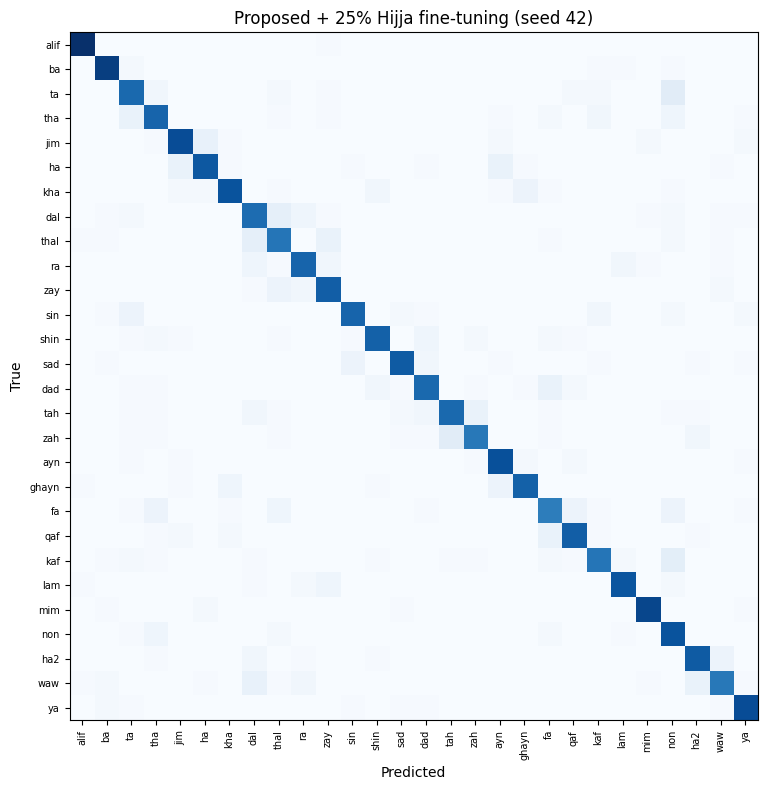

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

NAMES = ["alif","ba","ta","tha","jim","ha","kha","dal","thal","ra","zay","sin","shin",
         "sad","dad","tah","zah","ayn","ghayn","fa","qaf","kaf","lam","mim","non","ha2","waw","ya"]

ft_prop, _ = finetune(proposed, 0.25, seed=42)
pred0 = proposed.predict(Xh_te, verbose=0).argmax(axis=1)
pred1 = ft_prop.predict(Xh_te, verbose=0).argmax(axis=1)

cm0 = confusion_matrix(yh_te, pred0, labels=range(28))
cm1 = confusion_matrix(yh_te, pred1, labels=range(28))
acc0 = cm0.diagonal() / cm0.sum(axis=1)
acc1 = cm1.diagonal() / cm1.sum(axis=1)

per_letter = pd.DataFrame({"letter": NAMES, "before FT": acc0.round(3), "after FT 25%": acc1.round(3)})
print(per_letter.sort_values("after FT 25%").head(8).to_string(index=False))
print("Best 5 after FT:")
print(per_letter.sort_values("after FT 25%").tail(5).to_string(index=False))
per_letter.to_csv("processed/per_letter_accuracy.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(cm1, cmap="Blues")
ax.set_xticks(range(28)); ax.set_xticklabels(NAMES, rotation=90, fontsize=7)
ax.set_yticks(range(28)); ax.set_yticklabels(NAMES, fontsize=7)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Proposed + 25% Hijja fine-tuning (seed 42)")
plt.tight_layout()
plt.savefig("processed/confusion_matrix.png", dpi=200)
plt.show()

# 14. Per-Letter Visualization


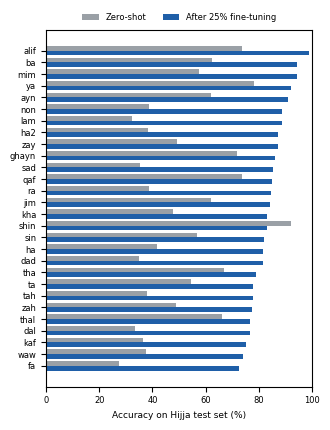

In [ ]:
per_letter = per_letter.sort_values("after FT 25%")
fig, ax = plt.subplots(figsize=(3.4, 4.4))
y = list(range(len(per_letter)))
ax.barh([i + 0.2 for i in y], per_letter["before FT"] * 100, height=0.4, color="#9aa0a6", label="Zero-shot")
ax.barh([i - 0.2 for i in y], per_letter["after FT 25%"] * 100, height=0.4, color="#1f5fa8", label="After 25% fine-tuning")
ax.set_yticks(y); ax.set_yticklabels(per_letter["letter"], fontsize=6)
ax.tick_params(axis="x", labelsize=6)
ax.set_xlabel("Accuracy on Hijja test set (%)", fontsize=6.5)
ax.set_xlim(0, 100)
ax.legend(fontsize=6, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig("processed/per_letter_accuracy.png", dpi=300)
plt.show()

# 15. Save and Download All Outputs


In [ ]:
!zip -r -q outputs.zip processed
from google.colab import files
files.download("outputs.zip")
